<div align="center">
  <img src="https://capsule-render.vercel.app/api?type=waving&color=0:0f2027,50:203a43,100:2c5364&height=200&section=header&text=Deep%Learning%20Projet&fontSize=50&fontColor=ffffff&animation=fadeIn&fontAlignY=38&desc=Fall%20Semester%202026/2027&descAlignY=58&descSize=18" width="100%" alt="banner"/>
</div>

<h2 align="center">Team</h2>

<table align="center">
  <tr>
    <td align="center">
      <a href="https://github.com/USER0">
        <img src="https://github.com/USER0.png" width="100" style="border-radius:50%" alt="Nome 0"/><br/>
        <b>Carlota Marto 20241729</b>
      </a>
    </td>
    <td align="center">
      <a href="https://github.com/DiogoCapelaGoncalves">
        <img src="https://github.com/DiogoCapelaGoncalves.png" width="100" style="border-radius:50%" alt="Nome 1"/><br/>
        <b>Diogo Capela 20241817</b>
      </a>
    </td>
    <td align="center">
      <a href="https://github.com/USER2">
        <img src="https://github.com/USER2.png" width="100" style="border-radius:50%" alt="Nome 2"/><br/>
        <b>Henrique Santos 20241752</b>
    <td align="center">
      <a href="https://github.com/USER4">
        <img src="https://github.com/USER4.png" width="100" style="border-radius:50%" alt="Nome 4"/><br/>
        <b>Laura Lisboa 20241783</b>
      </a>
    </td>
    <td align="center">
      <a href="https://github.com/tiago2806">
        <img src="https://github.com/tiago2806.png" width="100" style="border-radius:50%" alt="Nome 5"/><br/>
        <b>Homo Maximus 20241728</b>
      </a>
    </td>
  </tr>
</table>

<table align="center">
  <tr>
    <th>Índice</th>
  </tr>
  <tr>
    <td><a href="#sobre">1. Sobre</a></td>
  </tr>
  <tr>
    <td><a href="#instalação">2. Instalação</a></td>
  </tr>
  <tr>
    <td><a href="#utilização">3. Utilização</a></td>
  </tr>
  <tr>
    <td><a href="#resultados">4. Resultados</a></td>
  </tr>
  <tr>
    <td><a href="#equipa">5. Equipa</a></td>
  </tr>
</table>

Imports

In [2]:
import pandas as pd
import tensorflow as tf
import os
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

Labels Dataset Import

In [3]:
labels = pd.read_csv(r'C:/Users/diogo/Downloads/Tiny_ImageNet_Project_2026_Students/labels.csv')

In [4]:
labels.head()

,filename,class_id,description
0,image_000001.JPEG,n03042490,cliff dwelling
1,image_000002.JPEG,n02793495,barn
2,image_000003.JPEG,n02793495,barn
3,image_000004.JPEG,n02793495,barn
4,image_000005.JPEG,n02793495,barn


In [7]:
directory = r'C:/Users/diogo/Downloads/Tiny_ImageNet_Project_2026_Students/images'

In [8]:
image_names = labels['filename'].values

In [9]:
labels_encoded = labels['class_id'].astype('category').cat.codes.values
print(labels_encoded)

[ 91  66  66 ... 163 163 163]


In [10]:
image_paths = [os.path.join(directory, fname) for fname in image_names]
print(image_paths[:5])

['C:/Users/diogo/Downloads/Tiny_ImageNet_Project_2026_Students/images\\image_000001.JPEG', 'C:/Users/diogo/Downloads/Tiny_ImageNet_Project_2026_Students/images\\image_000002.JPEG', 'C:/Users/diogo/Downloads/Tiny_ImageNet_Project_2026_Students/images\\image_000003.JPEG', 'C:/Users/diogo/Downloads/Tiny_ImageNet_Project_2026_Students/images\\image_000004.JPEG', 'C:/Users/diogo/Downloads/Tiny_ImageNet_Project_2026_Students/images\\image_000005.JPEG']


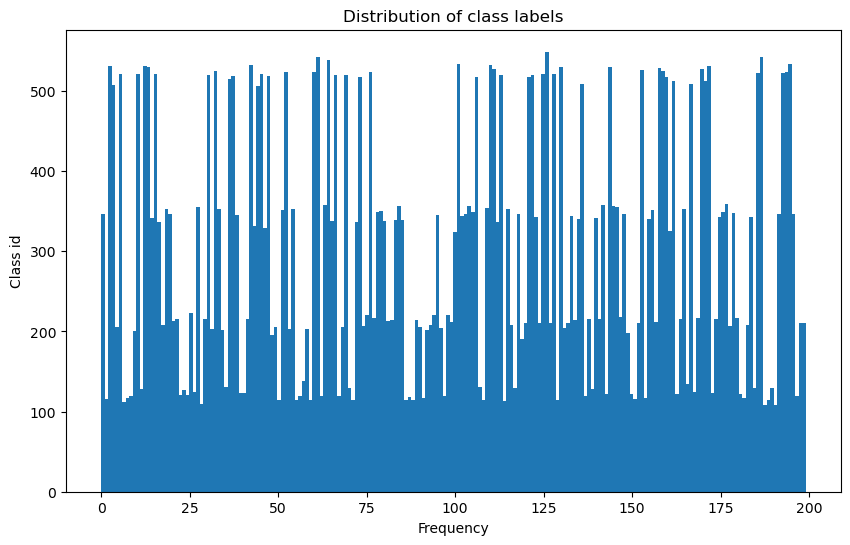

In [11]:
plt.figure(figsize=(10,6))
plt.hist(labels_encoded, bins=200)
plt.title("Distribution of class labels")
plt.xlabel("Frequency")
plt.ylabel("Class id")
plt.show()

In [12]:
image_size = (64,64)
batch_size = 32

def get_image(image_path, label):
    image = tf.io.read_file(image_path) # Go to the address and grab the file
    image = tf.image.decode_jpeg(image, channels = 3) # Turn the file into numbers (the colour of each pixel).
    image = image / 255 # Make the numbers smaller (0 to 1 instead of 0 to 255), which helps the model learn.
    return image, label # Hand back the photo and its answer together.

In [13]:
train_paths, temp_paths, train_y, temp_y = train_test_split(
    image_paths, labels_encoded, test_size=0.3, stratify=labels_encoded, random_state=42)

val_paths, test_paths, val_y, test_y = train_test_split(
    temp_paths, temp_y, test_size=0.5, stratify=temp_y, random_state=42)

In [14]:
def make_dataset(paths, labels, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(len(paths))
    ds = ds.map(get_image)
    return ds.batch(batch_size)

In [15]:
train_ds = make_dataset(train_paths, train_y, shuffle=True)
val_ds = make_dataset(val_paths, val_y)
test_ds = make_dataset(test_paths, test_y)

In [16]:
for images, labels_batch in train_ds.take(1):
    print(images.shape)

(32, 64, 64, 3)


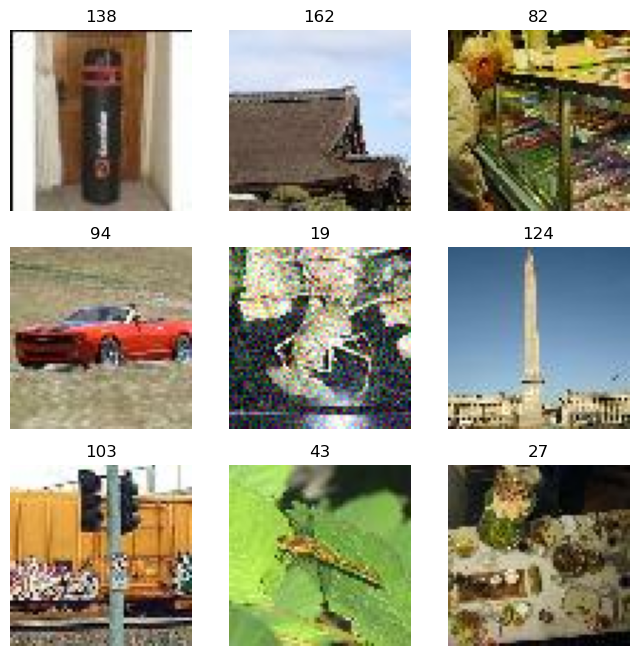

In [17]:
import matplotlib.pyplot as plt

for images, labels_batch in train_ds.take(1):
    plt.figure(figsize=(8, 8))
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i])
        plt.title(labels_batch[i].numpy())
        plt.axis('off')
    plt.show()

In [18]:
from tensorflow.keras import Sequential, regularizers
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPooling2D, Input

model = Sequential()
model.add(Input(shape=(64, 64, 3)))
model.add(Conv2D(32, 3, activation='relu'))
model.add(MaxPooling2D())
model.add(Conv2D(64, 3, activation='relu'))
model.add(MaxPooling2D())
model.add(Flatten())
model.add(Dense(128, kernel_regularizer=regularizers.l2(0.001), activation='relu'))
model.add(Dense(200, activation='softmax'))

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,605,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 200)            │        25,800 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,650,952 (6.30 MB)

 Trainable params: 1,650,952 (6.30 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
history = model.fit(train_ds, validation_data=val_ds, epochs=10)

Epoch 1/10


c:\Users\diogo\anaconda3\envs\NOVAIMS\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1313/1313 ━━━━━━━━━━━━━━━━━━━━ 36s 27ms/step - accuracy: 0.0400 - loss: 4.9910 - val_accuracy: 0.0649 - val_loss: 4.8049
Epoch 2/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 44s 33ms/step - accuracy: 0.0874 - loss: 4.6688 - val_accuracy: 0.1098 - val_loss: 4.5743
Epoch 3/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 40s 30ms/step - accuracy: 0.1181 - loss: 4.4715 - val_accuracy: 0.1229 - val_loss: 4.4777
Epoch 4/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 26s 19ms/step - accuracy: 0.1390 - loss: 4.3499 - val_accuracy: 0.1294 - val_loss: 4.4287
Epoch 5/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 20s 15ms/step - accuracy: 0.1515 - loss: 4.2662 - val_accuracy: 0.1404 - val_loss: 4.4222
Epoch 6/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 20s 15ms/step - accuracy: 0.1636 - loss: 4.2048 - val_accuracy: 0.1450 - val_loss: 4.3952
Epoch 7/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 24s 19ms/step - accuracy: 0.1719 - loss: 4.1583 - val_accuracy: 0.1463 - val_loss: 4.4248
Epoch 8/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 51s 26ms/step - accuracy: 0.1807 - loss: 4.11

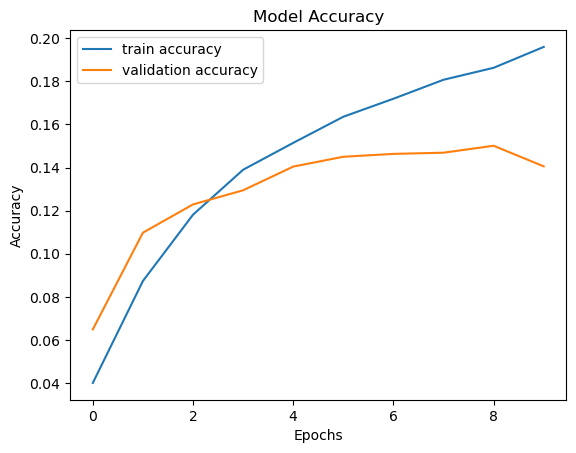

In [24]:
plt.plot(history.history["accuracy"], label = "train accuracy")
plt.plot(history.history["val_accuracy"], label = "validation accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()


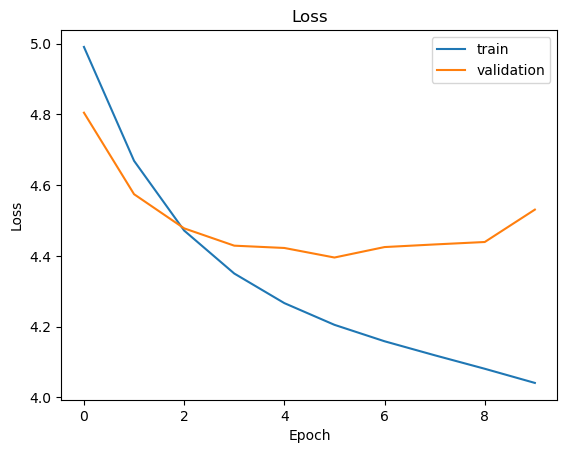

In [21]:
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [22]:
model.evaluate(test_ds)

282/282 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.1408 - loss: 4.5312


[4.531234264373779, 0.14077778160572052]